In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
from pathlib import Path

root_dir = Path.cwd().parent
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))
from matplotlib import pyplot as plt

import numpy as np
import copy
import caiman
from caiman.motion_correction import MotionCorrect
from utils.parameters import CaImAn as CaImAn_params

from caiman.source_extraction import cnmf as cnmf

In [2]:
prefix = "results"
suffix = "_test"
save_type = "hdf5"
use_parallel = True
n_processes = 12

session_path = Path("../../../../data/KotaroData/493_copy/Session02/")
path_to_stack = [str(file) for file in session_path.iterdir() if file.suffix == ".tif"][
    0
]

path_tmp = Path(session_path)
os.environ["CAIMAN_TEMP"] = str(path_tmp)
path_to_motion_correct = [
    str(file) for file in session_path.iterdir() if file.suffix == ".mmap"
][0]
resultFile_name = path_tmp / f"{prefix}_{Path(path_to_stack).stem}{suffix}"

save_path = session_path / "results.hdf5"

In [3]:
if "dview" in locals():  # 'locals' contains list of current local variables
    print("Closing previous cluster")
    caiman.stop_server(dview=dview)

if use_parallel:
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_obj = cnmf.cnmf.load_CNMF(save_path, n_processes=n_processes, dview=dview)

Datafile ../../../../data/KotaroData/493_copy/Session02/results.hdf5 not marked as cnmf


[   0    1    2 ... 1576 1577 1578]


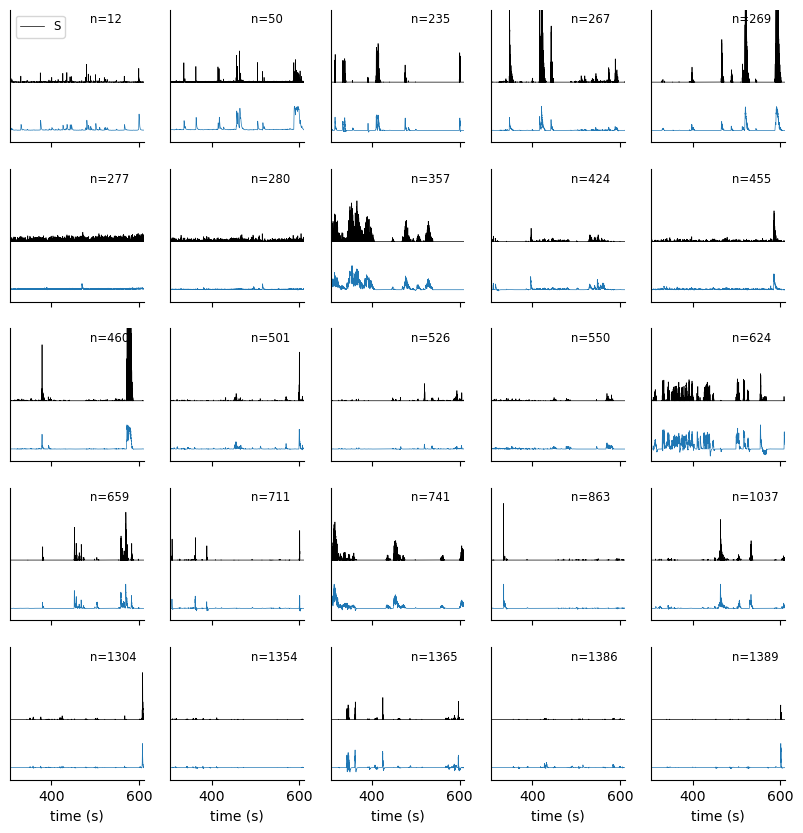

In [16]:
from image_processing.neuron_detection import plot_traces, plot_contours

# cnmf_obj.estimates.F_dff
plot_traces(cnmf_obj.estimates, f=15.0)

In [2]:
def ar2_to_tau(a1, a2, f):
    dt = 1 / f
    discriminant = a1**2 + 4 * a2
    lambda1 = (a1 + np.sqrt(discriminant)) / 2
    lambda2 = (a1 - np.sqrt(discriminant)) / 2
    tau1 = -dt / np.log(np.abs(lambda1))
    tau2 = -dt / np.log(np.abs(lambda2))
    return tau1, tau2


def tau_to_ar2(tau1, tau2, f):
    dt = 1 / f
    lambda1 = np.exp(-dt / tau1)
    lambda2 = np.exp(-dt / tau2)
    a1 = lambda1 + lambda2
    a2 = -lambda1 * lambda2
    return a1, a2


GCaMP6s = (0.18, 0.58)
GCaMP6m = (0.1, 0.289)
GCaMP6f = (0.03, 0.15)

In [3]:
tau_to_ar2(*GCaMP6f, 15)

(0.7495484116518505, -0.06948345122280153)

In [ ]:
params = copy.deepcopy(CaImAn_params)
params["fnames"] = [path_to_motion_correct]
params["fr"] = 15.0
params["p"] = 2
params["decay_time"] = 0.4  # GCaMP6f[1]
params["optimize_g"] = False
params["sniper_mode"] = False  # otherwise, returns progress bar on every step....
params["epochs"] = 2

opts = cnmf.params.CNMFParams(params_dict=params)

if "dview" in locals():  # 'locals' contains list of current local variables
    print("Closing previous cluster")
    caiman.stop_server(dview=dview)

if use_parallel:
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_obj = cnmf.online_cnmf.OnACID(params=opts, dview=dview)
cnmf_obj.fit_online()
# cnmf_obj.initialize_online(model_LN=None)
# Y = caiman.load(fname, outtype=np.float16)

cnmf_obj.save(str(save_path))

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)
OpenCV: FFMPEG: tag 0x34363248/'H264' is not supported with codec id 27 and format 'mp4 / MP4 (MPEG-4 Part 14)'
OpenCV: FFMPEG: fallback to use tag 0x31637661/'avc1'
Now processing file ../../../../data/KotaroData/493_copy/Session02/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in ""
Now processing file ../../../../data/KotaroData/493_copy/Session02/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
/home/wollex/miniforge3/envs/caiman/lib/python3.11/site-packages/caiman/components_evaluation.py:112: RuntimeWarning: invalid value encountered in divide
  sd_r = np.sqrt(np.sum(ff1**2, 1) / Ns)


In [5]:
def plot_contours(
    est, display_numbers=False, thr=0.2, thr_method="max", figure_path=None
):

    img = cnmf_obj.estimates.Cn
    if est.coordinates is None:  # not hasattr(self, 'coordinates'):
        est.coordinates = caiman.utils.visualization.get_contours(
            est.A, img.shape, thr=thr, thr_method=thr_method
        )

    plt.figure(figsize=(20, 10))
    coor_g = [est.coordinates[cr] for cr in est.idx_components]
    plt.subplot(1, 2, 1)
    caiman.utils.visualization.plot_contours(
        est.A[:, cnmf_obj.estimates.idx_components],
        img,
        coordinates=coor_g,
        display_numbers=display_numbers,
        cmap="viridis",
    )
    plt.setp(plt.gca(), xlim=(0, img.shape[1]), ylim=(img.shape[0], 0))
    plt.title(f"Accepted Components (n={len(est.idx_components)})")

    # bad = list(set(range(self.A.shape[1])) - set(cnmf_obj.estimates.idx_components))
    coor_b = [est.coordinates[cr] for cr in est.idx_components_bad]
    plt.subplot(1, 2, 2)
    caiman.utils.visualization.plot_contours(
        est.A[:, est.idx_components_bad],
        img,
        coordinates=coor_b,
        display_numbers=display_numbers,
        cmap="viridis",
        colors="red",
    )
    plt.setp(plt.gca(), xlim=(0, img.shape[1]), ylim=(img.shape[0], 0))
    plt.title(f"Rejected Components (n={len(est.idx_components_bad)})")

    if figure_path is not None:
        plt.savefig(figure_path / "neuron_contours.png", dpi=150)


def plot_traces(est, f, n_plots=(5, 5), figure_path=None):

    T = est.C.shape[1]
    T_range = np.array([T // 2, T])
    t = np.linspace(*(T_range / f), T_range[1] - T_range[0])

    idxes = np.random.choice(est.idx_components, size=np.prod(n_plots), replace=False)
    idxes.sort()

    plt.figure(figsize=(10, 10))
    for i, n in enumerate(idxes):

        plt.subplot(*n_plots, i + 1)

        plt.plot(
            t,
            2 + est.S[n, slice(*T_range)],  # / np.max(est.S[n, :]),
            linewidth=0.5,
            color="k",
            label="S",
        )

        plt.plot(
            t,
            1 + est.F_dff[n, slice(*T_range)] / np.max(est.F_dff[n, :]),
            linewidth=0.5,
            color="tab:green",
            label="dF/F",
        )

        max_C = np.max(est.C[n, :])
        plt.plot(
            t,
            est.C[n, slice(*T_range)] / max_C,
            linewidth=0.5,
            color="tab:blue",
        )
        plt.plot(
            t,
            (est.C[n, slice(*T_range)] + est.R[n, slice(*T_range)])
            / max_C,  # / np.max(cnmf_obj.estimates.C[n, :]), linewidth=0.5
            linewidth=0.5,
            color="tab:orange",
            label="C",
        )

        plt.text(0.6, 0.9, f"{n=}", transform=plt.gca().transAxes, fontsize="small")

        plt.setp(plt.gca(), ylim=(-0.5, 5.0), yticks=[], xlim=(t[0], t[-1]))
        if i < (n_plots[0] - 1) * n_plots[1]:
            plt.gca().set_xticklabels([])
        else:
            plt.xlabel("time (s)")
        if i == 0:
            plt.legend(loc="upper left", fontsize="small")
        plt.gca().spines[["top", "right"]].set_visible(False)

    if figure_path is not None:
        plt.savefig(figure_path / "neuron_traces.png", dpi=150)


def clear_cnm(dic, retain=None, remove=None):

    if retain is None and remove is None:
        print("Please provide a list of keys to obtain in the structure")
        return

    if not (remove is None):
        keys = list(dic.__dict__.keys())
        for key in keys:
            if key in remove:
                setattr(dic, key, None)
                # dic.__dict__.pop(key)

    if not (retain is None):
        keys = list(dic.__dict__.keys())
        for key in keys:
            if key not in retain:
                setattr(dic, key, None)
                # dic.__dict__.pop(key)

    return dic

In [ ]:
from pprint import pprint

pprint(cnmf_obj.estimates.__dict__.keys())
for key in cnmf_obj.estimates.__dict__.keys():
    try:
        print(
            f"{key}: {cnmf_obj.estimates.__dict__[key].shape}, {sys.getsizeof(cnmf_obj.estimates.__dict__[key]) / (1024**2):.2f} MB"
        )
    except:
        print(f"{key}: no shape attribute")
# cnmf_obj.estimates.YrA.shape

dict_keys(['A', 'C', 'f', 'b', 'R', 'W', 'b0', 'YrA', 'S', 'sn', 'g', 'bl', 'c1', 'neurons_sn', 'lam', 'center', 'merged_ROIs', 'coordinates', 'F_dff', 'idx_components', 'idx_components_bad', 'SNR_comp', 'r_values', 'cnn_preds', 'ecc', 'noisyC', 'C_on', 'Ab', 'Cf', 'OASISinstances', 'CY', 'CC', 'Ab_dense', 'Yr_buf', 'mn', 'vr', 'ind_new', 'rho_buf', 'AtA', 'AtY_buf', 'sv', 'groups', 'dims', 'shifts', 'A_thr', 'discarded_components', 'time_new_comp', 'nr', 'Yres_buf', 'mean_buff'])
A: (262144, 1305), 0.00 MB
C: (1305, 9162), 0.00 MB
f: (2, 9162), 0.00 MB
b: (262144, 2), 2.00 MB
R: no shape attribute
W: no shape attribute
b0: no shape attribute
YrA: (1305, 9162), 45.61 MB
S: (1305, 9162), 0.00 MB
sn: (262144,), 0.00 MB
g: (100, 2), 0.00 MB
bl: no shape attribute
c1: (100,), 0.00 MB
neurons_sn: (100,), 0.00 MB
lam: (100,), 0.00 MB
center: no shape attribute
merged_ROIs: no shape attribute
coordinates: no shape attribute
F_dff: (1305, 9162), 45.61 MB
idx_components: no shape attribute
idx_

In [ ]:
## costly evaluations
f = cnmf_obj.params.get("data", "fr")

fname = path_to_motion_correct
cnmf_obj.estimates.detrend_df_f(
    quantileMin=8, frames_window=int(10 * f), flag_auto=False, use_residuals=False
)
print("Detrended df/f")
if "dview" in locals():  # 'locals' contains list of current local variables
    # print("Closing previous cluster")
    caiman.stop_server(dview=dview)

movie_corrected = caiman.load(fname, subindices=slice(0, None, 5), outtype=np.float16)
cnmf_obj.estimates.Cn = caiman.local_correlations(movie_corrected, swap_dim=False)

del movie_corrected
# cnmf_obj.estimates.Cn = caiman.load(
#     fname, subindices=slice(0, None, 2), outtype=np.float16
# ).local_correlations(swap_dim=False)
print("Calculated local correlations")

Yr, dims, num_frames = caiman.load_memmap(fname)
images = np.reshape(Yr.T, [num_frames] + list(dims), order="F")

c, dview, n_processes = caiman.cluster.setup_cluster(n_processes=6, single_thread=False)
cnmf_obj.estimates.dview = dview
cnmf_obj.estimates.compute_residuals(Yr)
del Yr
print("Computed residuals")

cnmf_obj.estimates.evaluate_components(images, cnmf_obj.params, dview=dview)
print("Evaluated components")

# Yr, dims, num_frames = caiman.load_memmap(fname)
del images

Detrended df/f
Calculated local correlations


Component 15 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 10 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 22 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 40 is only active jointly with neighboring components. Space correlation calculation might be unreliable.


50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Evaluated components


Num accepted/rejected: 980, 599
Inferred tau: (0.6327481054019937, 0.6327481054019937)


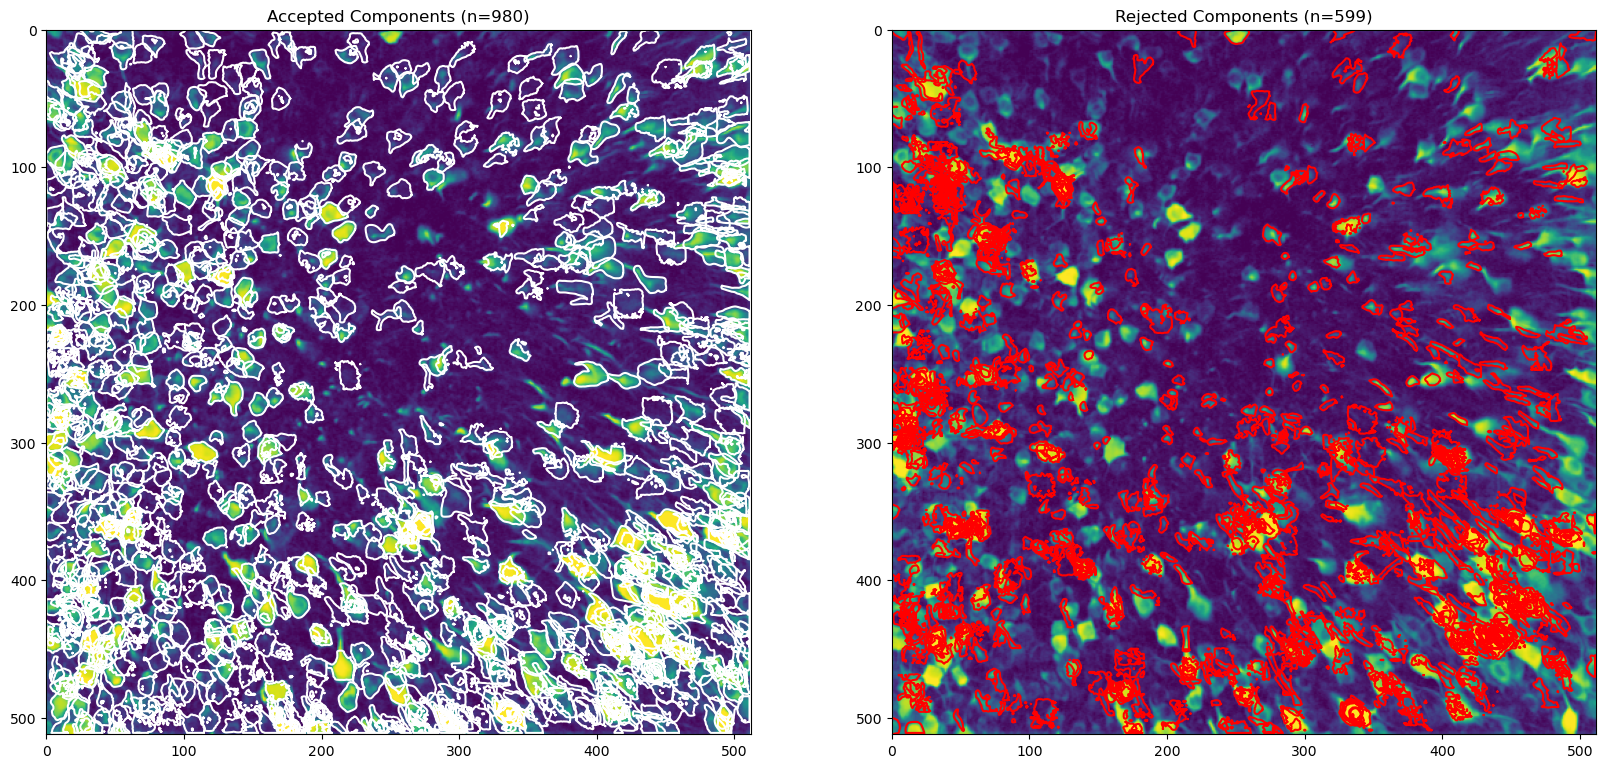

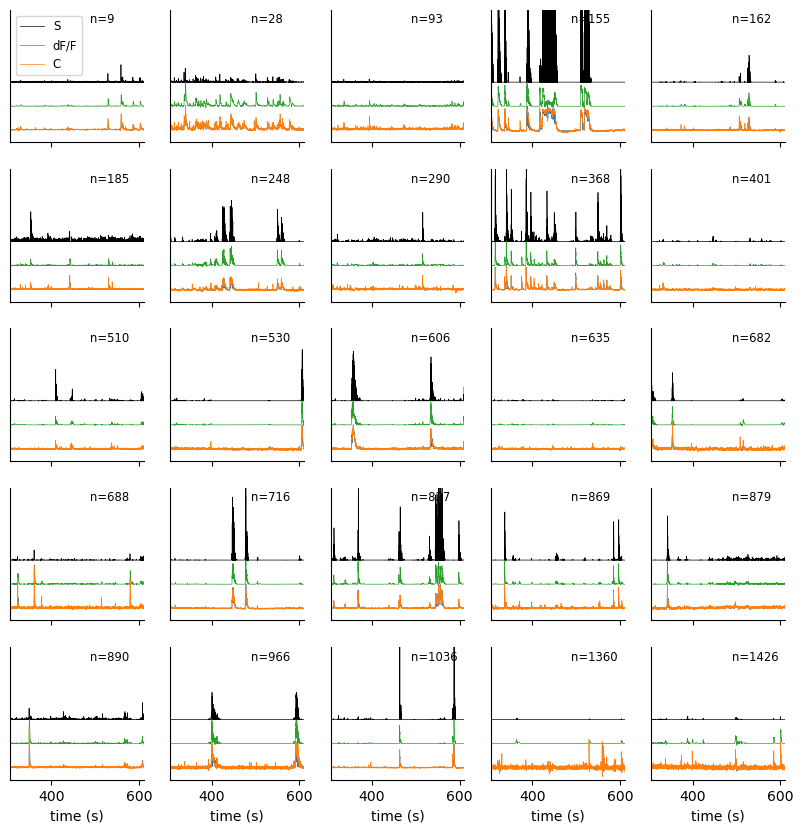

In [ ]:
border_thr = 5

cnmf_obj.estimates.coordinates = caiman.utils.visualization.get_contours(
    cnmf_obj.estimates.A, cnmf_obj.estimates.dims, thr=0.2, thr_method="max"
)

idx_border = []
for n in range(cnmf_obj.estimates.A.shape[1]):

    if (cnmf_obj.estimates.coordinates[n]["CoM"] < border_thr).any() or (
        cnmf_obj.estimates.coordinates[n]["CoM"]
        > (cnmf_obj.estimates.dims[0] - border_thr)
    ).any():
        idx_border.append(n)

cnmf_obj.estimates.idx_components = np.setdiff1d(
    cnmf_obj.estimates.idx_components, idx_border
)
cnmf_obj.estimates.idx_components_bad = np.union1d(
    cnmf_obj.estimates.idx_components_bad, idx_border
)

print(
    f"Num accepted/rejected: {len(cnmf_obj.estimates.idx_components)}, {len(cnmf_obj.estimates.idx_components_bad)}"
)
tau_inferred = ar2_to_tau(*cnmf_obj.estimates.g[0], f=f)
print(f"Inferred tau: {tau_inferred}")

figure_path = session_path / "figures"
figure_path.mkdir(exist_ok=True)

plot_contours(cnmf_obj.estimates, figure_path=figure_path)
plot_traces(cnmf_obj.estimates, f=f, figure_path=figure_path, n_plots=(5, 5))

In [240]:
def plot_key(
    ax,
    est,
    key,
    nbins=30,
    idx_good=None,
    idx_bad=None,
    flipped=False,
    styles=None,
):
    vals = getattr(est, key)

    idx_good = est.idx_components if idx_good is None else idx_good
    idx_bad = est.idx_components_bad if idx_bad is None else idx_bad
    val_range = np.percentile(vals[np.isfinite(vals)], [1, 99])

    for idxes, style in zip([idx_bad, idx_good], styles):
        if len(idxes) == 0:
            continue

        ax.hist(
            vals[idxes],
            bins=np.linspace(*val_range, nbins),
            orientation="horizontal" if flipped else "vertical",
            **style,
        )

        inf_mask = np.isinf(vals[idxes])
        if inf_mask.any():
            inf_count = inf_mask.sum()
            inf_pos = val_range[1] + (val_range[1] - val_range[0]) * 0.1
            if flipped:
                ax.barh(
                    inf_pos,
                    inf_count,
                    height=(val_range[1] - val_range[0]) / nbins,
                    **style,
                )
            else:
                ax.bar(
                    inf_pos,
                    inf_count,
                    width=(val_range[1] - val_range[0]) / nbins,
                    **style,
                )
            ax.text(
                inf_pos * 0.95,
                inf_count / 2 if flipped else inf_count,
                "inf",
                ha="center",
                va="center",
                fontsize=8,
            )

    if flipped:
        ax.invert_xaxis()
    ax.spines[["top", "left" if flipped else "right"]].set_visible(False)


def plot_scatter(ax, est, key_x, key_y, idx_bad=None):
    x_vals = getattr(est, key_x)
    y_vals = getattr(est, key_y)

    idx_bad = est.idx_components_bad if idx_bad is None else idx_bad

    ax.scatter(
        x_vals[idx_bad],
        y_vals[idx_bad],
        color="tab:red",
        s=4,
        alpha=0.7,
        label="bad",
    )
    ax.scatter(
        x_vals[est.idx_components],
        y_vals[est.idx_components],
        color="tab:green",
        s=2,
        alpha=0.7,
        label="good",
    )
    plt.setp(ax, xlabel=key_x, ylabel=key_y)
    ax.legend()


def plot_quality(est, figure_path=None):

    fig = plt.figure(figsize=(6, 6))
    styles = [{"color": "tab:red", "alpha": 0.7}, {"color": "tab:green", "alpha": 0.7}]

    bad_shape = est.cnn_preds < cnmf_obj.params.get("quality", "cnn_lowest")
    idx_bad_shape = np.where(bad_shape)[0]
    idx_bad_quality = np.setdiff1d(est.idx_components_bad, idx_bad_shape)
    # idx_bad = idx_quality_bad

    ## calculating the distance to the next border
    b_dist = np.zeros(cnmf_obj.estimates.A.shape[1])
    for n in range(est.A.shape[1]):
        border_distance_lower = est.coordinates[n]["CoM"]
        border_distance_upper = est.dims[0] - est.coordinates[n]["CoM"]
        b_dist[n] = np.min(np.minimum(border_distance_lower, border_distance_upper))

    bad_position = b_dist < border_thr

    bad_additional = bad_position | bad_shape
    idx_bad_additional = np.where(bad_additional)[0]
    idx_bad = np.union1d(est.idx_components_bad, idx_bad_additional)
    idx_good = np.setdiff1d(est.idx_components, idx_bad)

    # idx_bad_quality = np.where(bad_shape & ~bad_position)[0]
    # idx_add = idx_bad_additional
    idx_bad_filtered = np.setdiff1d(est.idx_components_bad, idx_bad_additional)

    print(idx_bad_filtered)

    ## plotting single quality statistics
    ax_cnn = plt.subplot(2, 2, 1)
    plot_key(ax_cnn, est, "cnn_preds", styles=styles)
    ax_cnn.axvline(
        cnmf_obj.params.get("quality", "cnn_lowest"), color="k", linestyle="--"
    )
    plt.setp(ax_cnn, xlabel="CNN Prediction", ylabel="Count")
    ax_cnn.text(
        0.7,
        0.9,
        f"n={bad_shape.sum()} discarded from cnn",
        transform=ax_cnn.transAxes,
        ha="center",
    )

    ax_snr = plt.subplot(2, 2, 2)
    plot_key(
        ax_snr,
        est,
        "SNR_comp",
        idx_good=idx_good,
        idx_bad=idx_bad_filtered,
        styles=styles,
    )
    plt.setp(ax_snr, xlabel="SNR", ylabel="Count")

    ax_rval = plt.subplot(2, 2, 3)
    plot_key(
        ax_rval,
        est,
        "r_values",
        idx_good=idx_good,
        idx_bad=idx_bad_filtered,
        flipped=True,
        styles=styles,
    )
    plt.setp(ax_rval, xlabel="Count", yticklabels=[])
    ax_rval.yaxis.tick_right()

    ax = fig.add_subplot([0.25, 0.74, 0.15, 0.15])
    ax.hist(b_dist[idx_bad_quality], np.logspace(0, 2.5, 51), **styles[0])
    ax.hist(
        b_dist[cnmf_obj.estimates.idx_components], np.logspace(0, 2.5, 51), **styles[1]
    )
    ax.axvline(border_thr, color="k", linestyle="--", linewidth=0.5)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_xscale("log")
    plt.setp(ax, xlabel="border distance [px]", yticks=[])
    ax.text(
        0.7,
        0.9,
        f"n={(b_dist<border_thr).sum()} discarded from border",
        transform=ax.transAxes,
        ha="center",
    )

    ax = plt.subplot(2, 2, 4)
    plot_scatter(ax, est, "SNR_comp", "r_values", idx_bad=idx_bad_filtered)
    plt.setp(
        ax,
        xlim=ax_snr.get_xlim(),
        ylim=ax_rval.get_ylim(),
        xlabel="SNR",
        ylabel="r value",
    )
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    if figure_path is not None:
        plt.savefig(figure_path / "neuron_quality.png", dpi=150)

[ 769  972 1391 1399]


/tmp/ipykernel_1371468/280106806.py:183: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


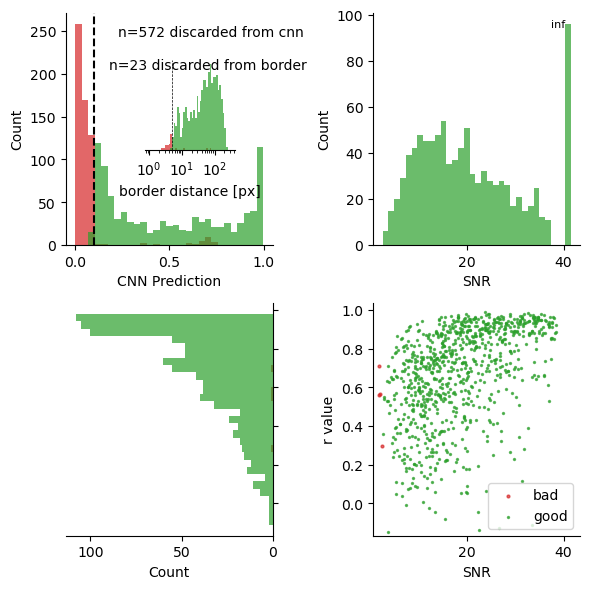

In [241]:
plot_quality(cnmf_obj.estimates, figure_path=session_path / "figures")

In [210]:
(~np.isfinite(cnmf_obj.estimates.SNR_comp))[cnmf_obj.estimates.idx_components_bad].sum()

32

In [31]:
cnmf_obj.params.get_group("quality")

{'SNR_lowest': 1.0,
 'cnn_lowest': 0.1,
 'gSig_range': None,
 'min_SNR': 2.5,
 'min_cnn_thr': 0.9,
 'rval_lowest': -1,
 'rval_thr': 0.8,
 'use_cnn': True,
 'use_ecc': False,
 'max_ecc': 3}

In [ ]:
cnmf_obj.estimates.select_components(use_object=True, save_discarded_components=False)

retain_keys = [
    "A",
    "C",
    "S",
    "F_dff",
    "b",
    "f",
    "R",
    "Cn",
    "dims",
    "coordinates",  # need this?
    "center",
    "SNR_comp",
    "r_values",
    "cnn_preds",
    "sn",
    "bl",
    "c1",
    "neurons_sn",
    "g",
    "YrA",
    # "idx_components",
    # "idx_components_bad",
]
cnmf_obj.estimates = clear_cnm(cnmf_obj.estimates, retain=retain_keys)
# residuals? noise? further?
save_path = session_path / "results_cleaned.hdf5"
cnmf_obj.save(str(save_path))

*** Variable g has not the same number of components as A ***


AttributeError: 'Estimates' object has no attribute 'bl'

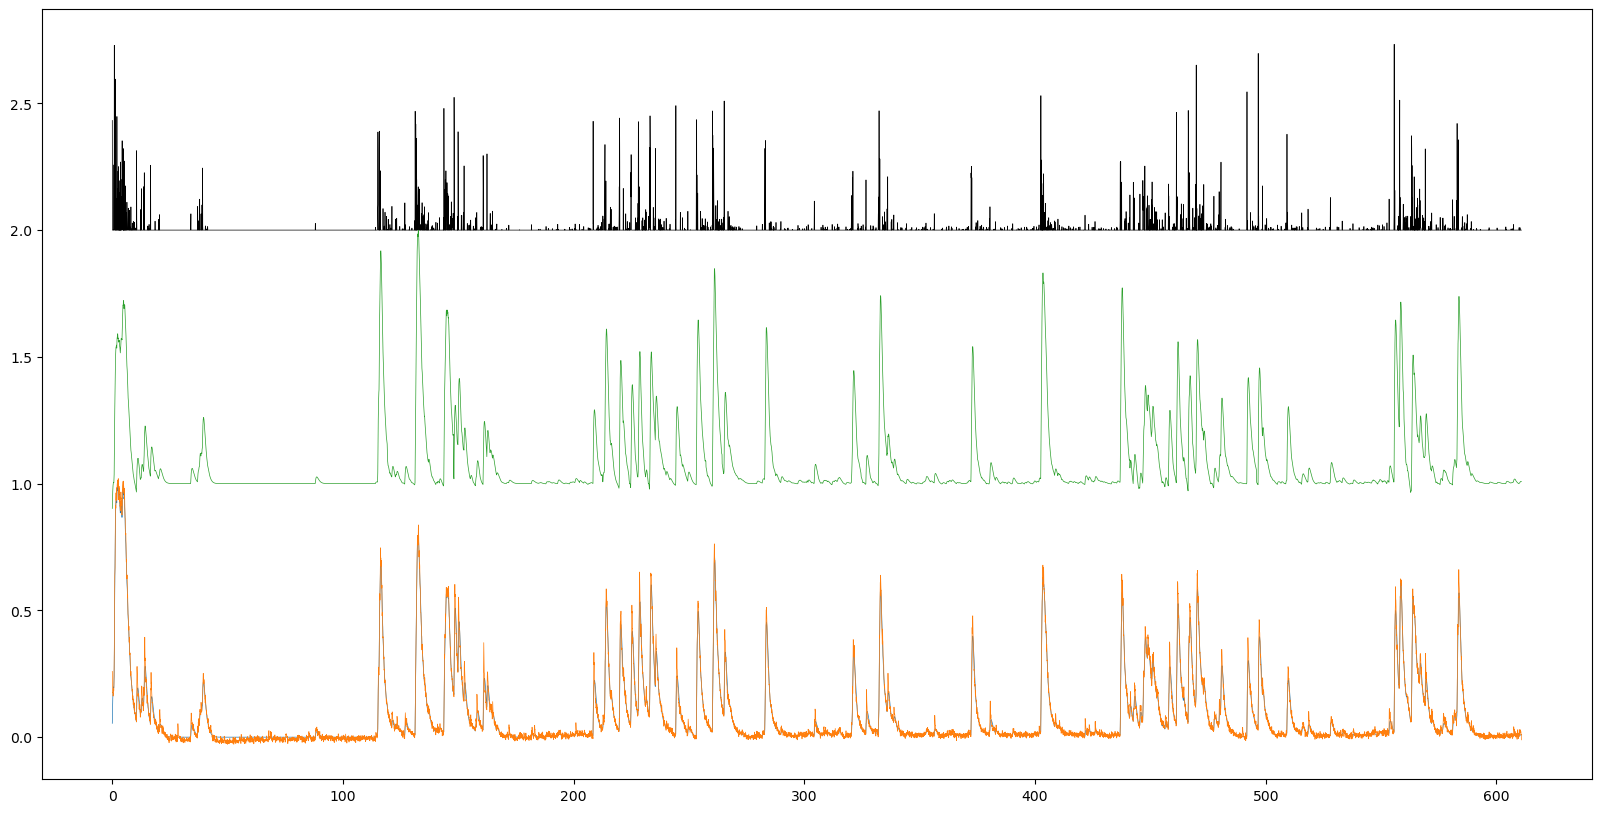

In [246]:
est = cnmf_obj.estimates
n = 5
plt.figure(figsize=(20, 10))
T_range = [0, est.C.shape[1]]
t = np.linspace(*(T_range / f), T_range[1] - T_range[0])
plt.plot(
    t,
    2 + est.S[n, slice(*T_range)],  # / np.max(est.S[n, :]),
    linewidth=0.5,
    color="k",
    label="S",
)

plt.plot(
    t,
    1 + est.F_dff[n, slice(*T_range)] / np.max(est.F_dff[n, :]),
    linewidth=0.5,
    color="tab:green",
    label="dF/F",
)

max_C = np.max(est.C[n, :])
plt.plot(
    t,
    est.C[n, slice(*T_range)] / max_C,
    linewidth=0.5,
    color="tab:blue",
)
plt.plot(
    t,
    (est.C[n, slice(*T_range)] + est.R[n, slice(*T_range)])
    / max_C,  # / np.max(cnmf_obj.estimates.C[n, :]), linewidth=0.5
    linewidth=0.5,
    color="tab:orange",
    label="C",
)

In [83]:
key = "Cn"
print(
    f"{key}: {getattr(cnmf_obj.estimates, key).shape}, {getattr(cnmf_obj.estimates, key).dtype}, {sys.getsizeof(getattr(cnmf_obj.estimates, key)) / (1024):.2f} kB"
)

AttributeError: 'Estimates' object has no attribute 'Cn'

In [43]:
from time import time

frame_count = -1
Y_ = caiman.base.movies.load_iter(
    path_to_motion_correct,
    var_name_hdf5=cnmf_obj.params.get("data", "var_name_hdf5"),
    # subindices=slice(init_batc_iter[file_count], None, None))
    subindices=slice(0, None, None),
)
t = cnmf_obj.params.get("online", "init_batch")
frame = next(Y_)
frame_ = frame.copy().astype(np.float32)
frame_count += 1
t_frame_start = time()
frame_cor = frame_
cnmf_obj.fit_next(t, frame_cor.reshape(-1, order="F"))

Caiman OnACID Object A.shape=(262144, 100) bg components=2 C.shape=(100, 1000) Use str() for more details

In [ ]:
import cv2

cv2.destroyAllWindows()

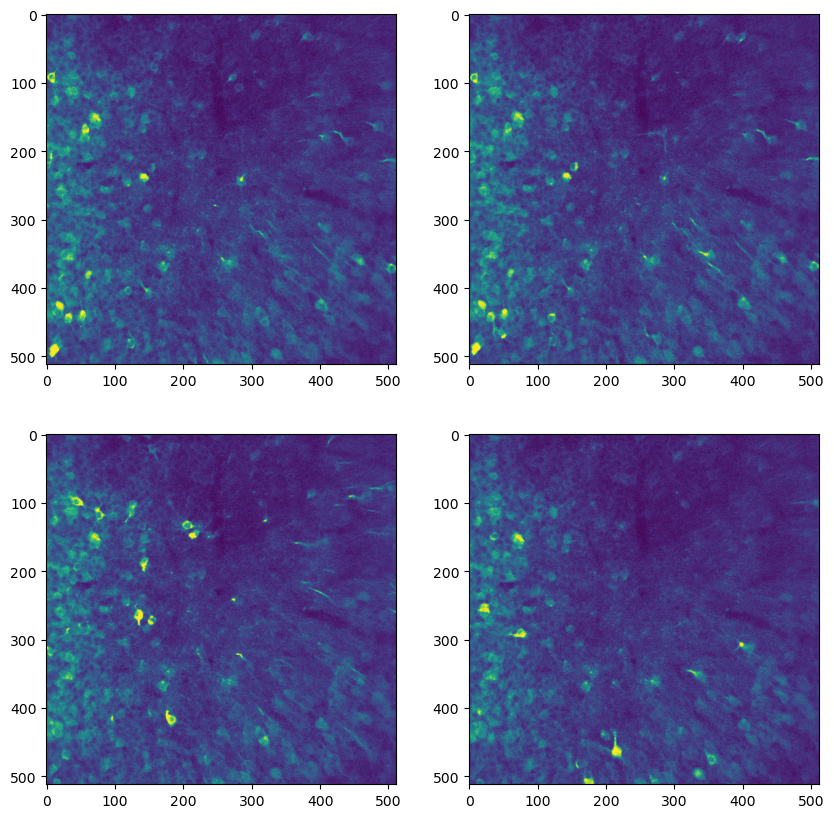

In [ ]:
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 10))
idxes = [0, 10, 100, 1000]
for i, idx in enumerate(idxes):
    plt.subplot(2, 2, i + 1)
    plt.imshow(Y[idx, ...])